# NUTRIPREDICT Colombia — Desnutrición aguda infantil (evento 113): LightGBM, XGBoost y Random Forest

**Qué se predice.** El número de **notificaciones** de desnutrición aguda infantil (evento 113) al sistema de vigilancia, por municipio y periodo, **un paso adelante** (se conocen los periodos anteriores). No mide incidencia real ni riesgo individual: cada fila de la base es una notificación y no hay identificador de paciente.

**Modelos comparados (solo estos tres):** LightGBM (objetivo Poisson) · XGBoost (objetivo Poisson) · Random Forest. Todos usan las mismas variables del notebook anterior (sin cambios), construidas solo con información hasta *t-1*; ninguna se ajusta con la prueba.

| Partición | Periodo | Uso |
|---|---|---|
| Entrenamiento | 2017–2022 | ajusta los modelos (2016 solo calienta los rezagos) |
| Validación | 2023 | elige hiperparámetros **y el mejor modelo** |
| Prueba final | 2024–2025 | **solo se evalúa, una vez**; no elige modelos, variables ni hiperparámetros |

El análisis **mensual** (municipio-mes) y el **semanal** (municipio-semana epidemiológica) se reportan por separado. Niveles: municipal (donde se entrena), departamental y nacional (sumas de las predicciones municipales). Métricas: MAE, RMSE, R² y WMAPE (%), sin mezclar frecuencias ni niveles.

| Etapa | Contenido |
|---|---|
| 0 | Configuración, calendario epidemiológico, variables sin fuga, métricas |
| 1 | Carga del Excel y calidad de datos (exclusiones, fechas, DIVIPOLA) |
| 2 | Paneles mensual y semanal, conciliación de totales y variables |
| 3 | Ajuste de los tres modelos (hiperparámetros: entrenamiento → validación) |
| 4 | Selección en validación, evaluación final en prueba y gráficos |
| 5 | Pronóstico exploratorio de 12 meses (recursivo) y escenarios anuales 2026-2030 (**no validados**) |
| 5b | Escenarios anuales 2026-2030 (extrapolación de tendencia, **ajena a los tres modelos y no validada**) |
| 6 | Priorización territorial y exportación |

*Ejecutar las celdas en orden.* La mensual usa el año calendario del mes y la semanal el año epidemiológico para asignar las particiones.

## 0. Configuración común
Rutas, particiones, calendario epidemiológico (semana domingo-sábado; la semana 1 contiene el 4 de enero), variables (`construir_features`, solo información hasta *t-1*), los tres modelos y las métricas.

In [3]:
import os, json, time, warnings, unicodedata
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import nbinom, spearmanr
from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_poisson_deviance
from sklearn.model_selection import ParameterSampler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
warnings.filterwarnings('ignore')
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3})

try:
    from google.colab import drive
    drive.mount('/content/drive'); BASE = '/content/drive/MyDrive'
except ImportError:                    # ejecución local
    BASE = os.environ.get('NUTRI_BASE', '.')

SEMILLA = 42
_ARCHIVOS = dict(
    excel='datos_unificados_113_2016_2025.xlsx',                      # entrada: no se modifica
    base='desnutricion_113_limpio_2016_2025.parquet', calidad='calidad_datos_2016_2025.json',
    panel_M='df_panel_estructurado_2016_2025.parquet',                # municipio-mes
    panel_W='df_panel_semanal_2016_2025.parquet',                     # municipio-semana epidemiológica
    ml_M='df_ml_preparado_2016_2025.parquet', ml_W='df_ml_semanal_2016_2025.parquet',
    pred_M='df_predicciones_evaluadas_2016_2025.parquet', pred_W='df_predicciones_semanales_2016_2025.parquet',
    tabla='tabla_comparativa_modelos.csv', seleccion='seleccion_modelos.json',
    excel_res='NUTRIPREDICT_COLOMBIA_RESULTADOS_2016_2025.xlsx', json_php='resultados_nutripredict_2016_2025.json')
RUTAS = {k: f'{BASE}/{v}' for k, v in _ARCHIVOS.items()}
RUTAS['poblacion'] = None              # CSV opcional con columnas DIVIPOLA, POBLACION (menores de 5 años, DANE); no se inventa población

# ---- Particiones temporales (por año calendario del mes / año epidemiológico) ----
ANIOS_TRAIN = (2017, 2022)             # entrenamiento (2016 solo "calienta" los rezagos)
ANIO_VAL = 2023                        # validación: elige hiperparámetros y modelo
ANIOS_TEST = (2024, 2025)              # prueba final: solo evalúa

def asignar_split(anio):
    a = pd.Series(anio)
    return np.select([a.between(*ANIOS_TRAIN), a == ANIO_VAL, a.between(*ANIOS_TEST)], ['train', 'val', 'test'], default='otro')

def mascaras(d):
    """Máscaras booleanas (train, val, test) según la columna SPLIT."""
    return tuple(d['SPLIT'] == s for s in ('train', 'val', 'test'))

# Códigos de departamento DIVIPOLA reconocidos (33). Es una lista de departamentos, NO el catálogo municipal oficial.
DEPTOS_VALIDOS = {'05','08','11','13','15','17','18','19','20','23','25','27','41','44','47','50','52','54','63','66','68',
                  '70','73','76','81','85','86','88','91','94','95','97','99'}

def norm_txt(s):
    sin_tildes = lambda x: ''.join(ch for ch in unicodedata.normalize('NFKD', x) if not unicodedata.combining(ch)) if isinstance(x, str) else x
    return s.astype('string').str.strip().str.upper().map(sin_tildes).astype('string')

# ---- Calendario epidemiológico (MMWR/OMS: semana domingo-sábado; la semana 1 contiene el 4 de enero) ----
def epi_inicio(anio, semana=1):
    ene4 = pd.Timestamp(int(anio), 1, 4)
    return ene4 - pd.Timedelta(days=(ene4.weekday() + 1) % 7) + pd.Timedelta(weeks=int(semana) - 1)

def n_semanas_epi(anio):
    return (epi_inicio(anio + 1) - epi_inicio(anio)).days // 7

def calendario_epi(anio_ini, anio_fin):
    filas = [(a, s, epi_inicio(a, s), epi_inicio(a, s) + pd.Timedelta(days=3))
             for a in range(anio_ini, anio_fin + 1) for s in range(1, n_semanas_epi(a) + 1)]
    cal = pd.DataFrame(filas, columns=['ANO_EPI', 'SEM_EPI', 'SEMANA_INI', 'SEMANA_MID'])
    cal['ANIO_MES_DT'] = cal['SEMANA_MID'].dt.to_period('M').dt.to_timestamp()   # mes de la mitad de la semana
    return cal

def epi_de_fecha(fechas):
    """(año_epi, semana_epi) de cada fecha (Series datetime)."""
    def f(d):
        y = d.year
        if d >= epi_inicio(y + 1): y += 1
        elif d < epi_inicio(y): y -= 1
        return y, (d - epi_inicio(y)).days // 7 + 1
    r = fechas.map({d: f(d) for d in pd.to_datetime(fechas.dropna().unique())})
    return r.map(lambda t: t[0] if isinstance(t, tuple) else np.nan), r.map(lambda t: t[1] if isinstance(t, tuple) else np.nan)

# ---- Configuración por frecuencia: M = municipio-mes, W = municipio-semana ----
FREQ = {
    'M': dict(nombre='mensual', fecha='ANIO_MES_DT', suf='M', lags=[1, 2, 3, 6, 12], rolls=[3, 6, 12],
              col_base='PROMEDIO_MOVIL_6M', lag_calentamiento=12, n_iter=12),
    'W': dict(nombre='semanal', fecha='SEMANA_INI', suf='S', lags=[1, 2, 4, 52], rolls=[4, 12],
              col_base='PROMEDIO_MOVIL_12S', lag_calentamiento=52, n_iter=6),
}

def lista_features(freq):
    c = FREQ[freq]; s = c['suf']
    f = [f'CASOS_LAG_{l}' for l in c['lags']] + [f'PROMEDIO_MOVIL_{w}{s}' for w in c['rolls']] + [f"STD_MOVIL_{c['rolls'][1]}{s}"]
    f += ['EWM_03', 'PCT_CERO_REC', 'MEDIA_HISTORICA', 'PROP_RURAL_HIST', 'PROP_INDIGENA_HIST', 'DEP_LAG_1', 'NAL_LAG_1', 'COD_DPTO']
    return f + (['SIN_MES', 'COS_MES'] if freq == 'M' else ['SIN_SEM', 'COS_SEM', 'SIN_SEM2', 'COS_SEM2'])

def construir_features(panel, freq):
    """Variables con información disponible hasta t-1 (rezagos y ventanas sobre la serie desplazada).
    Admite filas futuras con CASOS = NaN (pronóstico recursivo): nunca usan el valor de t."""
    c = FREQ[freq]; f = c['fecha']; s = c['suf']; w2 = c['rolls'][1]; U = 'DIVIPOLA_RESIDENCIA'
    df = panel.sort_values([U, f]).reset_index(drop=True)
    g = df.groupby(U, sort=False)
    for l in c['lags']:
        df[f'CASOS_LAG_{l}'] = g['CASOS'].shift(l)
    lag1 = df.groupby(U, sort=False)['CASOS_LAG_1']
    for w in c['rolls']:
        df[f'PROMEDIO_MOVIL_{w}{s}'] = lag1.transform(lambda x, w=w: x.rolling(w, min_periods=1).mean())
    df[f'STD_MOVIL_{w2}{s}'] = lag1.transform(lambda x: x.rolling(w2, min_periods=2).std()).fillna(0)
    df['EWM_03'] = lag1.transform(lambda x: x.ewm(alpha=0.3, adjust=False).mean())
    df['PCT_CERO_REC'] = lag1.transform(lambda x: x.eq(0).where(x.notna()).rolling(w2, min_periods=1).mean())
    df['MEDIA_HISTORICA'] = lag1.transform(lambda x: x.expanding().mean())
    cum_tot = g['CASOS'].cumsum()                       # proporciones rural / indígena acumuladas hasta t-1
    for col, nuevo in [('CASOS_RURAL', 'PROP_RURAL_HIST'), ('CASOS_INDIGENA', 'PROP_INDIGENA_HIST')]:
        df[nuevo] = (g[col].cumsum() / cum_tot.where(cum_tot > 0)).groupby(df[U], sort=False).shift(1).fillna(0)
    df['COD_DPTO'] = df[U].str[:2].astype(int)          # contexto departamental / nacional en t-1
    dep = df.groupby(['COD_DPTO', f])['CASOS'].sum(min_count=1).rename('DEP_CASOS').reset_index().sort_values(['COD_DPTO', f])
    dep['DEP_LAG_1'] = dep.groupby('COD_DPTO')['DEP_CASOS'].shift(1)
    nal = df.groupby(f)['CASOS'].sum(min_count=1).shift(1).rename('NAL_LAG_1').reset_index()
    df = df.merge(dep[['COD_DPTO', f, 'DEP_LAG_1']], on=['COD_DPTO', f], how='left').merge(nal, on=f, how='left')
    if freq == 'M':                                     # estacionalidad
        df['ANIO'] = df[f].dt.year; m = df[f].dt.month
        df['SIN_MES'] = np.sin(2 * np.pi * m / 12); df['COS_MES'] = np.cos(2 * np.pi * m / 12)
    else:
        df['ANIO'] = df['ANO_EPI']; sm_ = df['SEM_EPI'] / 52.18
        df['SIN_SEM'] = np.sin(2 * np.pi * sm_); df['COS_SEM'] = np.cos(2 * np.pi * sm_)
        df['SIN_SEM2'] = np.sin(4 * np.pi * sm_); df['COS_SEM2'] = np.cos(4 * np.pi * sm_)
    df['SPLIT'] = asignar_split(df['ANIO'])
    return df.sort_values([f, U]).reset_index(drop=True)

class ModeloTasa(BaseEstimator, RegressorMixin):
    """Aprende la TASA relativa al nivel reciente (casos / promedio móvil) con peso = nivel; reescala al predecir.
    Reduce el problema de que los árboles no extrapolan niveles."""
    def __init__(self, modelo=None, col_base='PROMEDIO_MOVIL_6M'):
        self.modelo = modelo; self.col_base = col_base
    def fit(self, X, y):
        b = X[self.col_base].to_numpy() + 0.5
        self.modelo_ = clone(self.modelo).fit(X, np.asarray(y) / b, sample_weight=b)
        return self
    def predict(self, X):
        return np.clip(self.modelo_.predict(X), 1e-6, None) * (X[self.col_base].to_numpy() + 0.5)

# ---- Los tres modelos y sus espacios de búsqueda (la búsqueda usa solo entrenamiento -> validación) ----
MODELOS = {
    'PRED_LGB': dict(nombre='LightGBM (Poisson)', div=1,
        crear=lambda freq: LGBMRegressor(objective='poisson', random_state=SEMILLA, verbose=-1, n_jobs=-1),
        espacio={'n_estimators': [200, 400, 800], 'learning_rate': [0.03, 0.05, 0.1], 'num_leaves': [15, 31, 63],
                 'min_child_samples': [20, 50, 100], 'subsample': [0.7, 0.9, 1.0], 'subsample_freq': [1],
                 'colsample_bytree': [0.7, 0.9, 1.0], 'reg_lambda': [0, 1, 10]}),
    'PRED_XGB': dict(nombre='XGBoost (Poisson)', div=1,
        crear=lambda freq: XGBRegressor(objective='count:poisson', tree_method='hist', random_state=SEMILLA, n_jobs=-1),
        espacio={'n_estimators': [200, 400, 800], 'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [3, 5, 7],
                 'min_child_weight': [1, 5, 10], 'subsample': [0.7, 0.9, 1.0], 'colsample_bytree': [0.7, 0.9, 1.0]}),
    'PRED_RF': dict(nombre='Random Forest', div=2,          # menos iteraciones de búsqueda (más lento)
        crear=lambda freq: RandomForestRegressor(random_state=SEMILLA, n_jobs=-1, **({'max_samples': 0.4} if freq == 'W' else {})),
        espacio={'n_estimators': [150, 250], 'max_depth': [8, 12], 'min_samples_leaf': [10, 20, 40], 'max_features': [0.5, 0.8]}),
}
PRED_COLS = list(MODELOS)

# ---- Métricas (mismas definiciones en todas las frecuencias y niveles) ----
def metricas(y, p):
    """MAE, RMSE, R² (1 − SSE/SST, con SST respecto de la media observada del nivel y la partición evaluados) y WMAPE (%) = 100·Σ|error| / Σ observado."""
    y = np.asarray(y, float); p = np.asarray(p, float); e = np.abs(y - p); sst = ((y - y.mean()) ** 2).sum()
    return {'MAE': e.mean(), 'RMSE': float(np.sqrt(((y - p) ** 2).mean())), 'R2': 1 - ((y - p) ** 2).sum() / sst if sst > 0 else np.nan,
            'WMAPE': 100 * e.sum() / y.sum() if y.sum() > 0 else np.nan}

def evaluar_nivel(d, pred_cols, keys, fecha, split):
    """Métricas de cada predicción al agregar d a `keys` + periodo (keys=[] -> nacional) en la partición `split`."""
    k = keys if keys else ['_NAL']
    a = d[d['SPLIT'] == split].assign(_NAL=1).groupby(k + [fecha])[['CASOS'] + pred_cols].sum().reset_index()
    return pd.DataFrame({c: metricas(a['CASOS'], a[c]) for c in pred_cols}).T, len(a)

# ---- Entrada / salida ----
def leer_json(ruta):
    if not os.path.exists(ruta): return {}
    with open(ruta, encoding='utf-8') as fh: return json.load(fh)

def guardar_json(obj, ruta, indent=2, **kw):
    with open(ruta, 'w', encoding='utf-8') as fh: json.dump(obj, fh, ensure_ascii=False, indent=indent, **kw)

def cargar_panel(freq):
    p = pd.read_parquet(RUTAS[f'panel_{freq}'])
    p['DIVIPOLA_RESIDENCIA'] = p['DIVIPOLA_RESIDENCIA'].astype(str).str.zfill(5)
    return p

def leer_poblacion():
    """Población DANE opcional (None si no hay CSV). Columnas del CSV: DIVIPOLA, POBLACION."""
    if not (RUTAS['poblacion'] and os.path.exists(RUTAS['poblacion'])): return None
    pob = pd.read_csv(RUTAS['poblacion'], dtype={'DIVIPOLA': str})
    pob['DIVIPOLA_RESIDENCIA'] = pob['DIVIPOLA'].str.zfill(5)
    return pob

print(f"Base: {BASE} | Train {ANIOS_TRAIN} | Val {ANIO_VAL} | Test {ANIOS_TEST} | Modelos: {', '.join(m['nombre'] for m in MODELOS.values())}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base: /content/drive/MyDrive | Train (2017, 2022) | Val 2023 | Test (2024, 2025) | Modelos: LightGBM (Poisson), XGBoost (Poisson), Random Forest


## 1. Carga del Excel y calidad de datos
Cada fila es una **notificación**; no hay identificador de paciente. Reglas de limpieza:
- Se elimina solo la repetición exacta de (`archivo_origen`, `CONSECUTIVE`). Las filas **idénticas salvo `CONSECUTIVE` no se eliminan** (podrían ser notificaciones distintas): solo se cuentan como indicador.
- `ANO` y `SEMANA` son la referencia (metodología del proyecto). `FEC_NOT` solo se contrasta: las diferencias **se informan por año y archivo, sin descartar ni corregir** registros.
- Se excluyen registros del exterior, con código territorial inválido o sin año/semana utilizable; se muestra cuántos y por qué. La validación DIVIPOLA comprueba formato (5 dígitos) y código de departamento contra una lista de 33; **no usa el catálogo municipal oficial** (no está en el proyecto).

In [4]:
COLUMNAS = ['archivo_origen', 'CONSECUTIVE', 'COD_EVE', 'ANO', 'SEMANA', 'FEC_NOT', 'AREA', 'PER_ETN',
            'COD_DPTO_R', 'COD_MUN_R', 'Departamento_residencia', 'Municipio_residencia']
hdr = pd.read_excel(RUTAS['excel'], sheet_name='Datos', nrows=0).columns.tolist()
id_paciente = [c for c in hdr if c.lower() in ('tip_ide_', 'num_ide_')]          # solo se comprueba su ausencia
print('Leyendo Excel (puede tardar 2-4 min la primera vez)...')
df = pd.read_excel(RUTAS['excel'], sheet_name='Datos', usecols=COLUMNAS, dtype=str)
for c in df.columns:
    df[c] = df[c].str.strip().replace('', pd.NA)
calidad = {'filas_leidas': int(len(df)), 'identificador_paciente_disponible': bool(id_paciente)}

# --- 1. Evento y duplicados ---
df = df[df['COD_EVE'] == '113'].copy()
calidad['filas_evento_113'] = int(len(df))
dup_clave = df.duplicated(['archivo_origen', 'CONSECUTIVE'])
calidad['duplicados_archivo_consecutive_eliminados'] = int(dup_clave.sum())
calidad['filas_identicas_salvo_consecutive_conservadas'] = int(df.drop(columns='CONSECUTIVE').duplicated().sum())
df = df[~dup_clave].copy()

# --- 2. Año, semana y fecha: se contrastan, no se corrigen ---
df['FEC_NOT'] = pd.to_datetime(df['FEC_NOT'], errors='coerce')
ano = pd.to_numeric(df['ANO'], errors='coerce').astype(float); sem = pd.to_numeric(df['SEMANA'], errors='coerce').astype(float)
df['ANO'], df['SEMANA'] = ano.astype('Int64'), sem.astype('Int64')
ok_as = ano.notna() & sem.notna()
nsem = ano.map(lambda a: n_semanas_epi(int(a)) if pd.notna(a) else np.nan)
fuera_cal = ok_as & ~((sem >= 1) & (sem <= nsem))
ano_f, sem_f = epi_de_fecha(df['FEC_NOT']); ano_f, sem_f = ano_f.astype(float), sem_f.astype(float)
cmp_ = df['FEC_NOT'].notna() & ok_as
df['_ANO_DIF'] = cmp_ & (ano_f != ano)                                   # año epi de FEC_NOT distinto de ANO
df['_SEM_DIF'] = cmp_ & (ano_f == ano) & ((sem_f - sem).abs() > 1)       # semanas de FEC_NOT y SEMANA difieren en más de 1

# --- 3. Territorio (DIVIPOLA de residencia) y motivo de exclusión (un solo motivo por fila, en este orden) ---
df['DIVIPOLA_RESIDENCIA'] = df['COD_DPTO_R'].fillna('').str.zfill(2) + df['COD_MUN_R'].fillna('').str.zfill(3)
cod = df['DIVIPOLA_RESIDENCIA']
b = lambda s: s.fillna(False).astype(bool).to_numpy()
exterior = b(norm_txt(df['Departamento_residencia']).fillna('').str.contains('EXTERIOR') | norm_txt(df['Municipio_residencia']).fillna('').str.contains('EXTERIOR'))
MOTIVOS = ['Residencia en el exterior', 'DIVIPOLA con formato inválido (no son 5 dígitos)', 'Código de departamento fuera de la lista de 33',
           'Código de municipio 000 (sin municipio)', 'ANO o SEMANA faltante', 'Semana fuera del calendario epidemiológico']
condiciones = [exterior, ~b(cod.str.fullmatch(r'\d{5}')), ~b(cod.str[:2].isin(DEPTOS_VALIDOS)), b(cod.str[2:] == '000'), ~b(ok_as), b(fuera_cal)]
df['MOTIVO_EXCLUSION'] = pd.Series(np.select(condiciones, MOTIVOS, default=''), index=df.index).replace('', pd.NA)
excl = df['MOTIVO_EXCLUSION'].value_counts().reindex(MOTIVOS, fill_value=0)
u = df[df['MOTIVO_EXCLUSION'].isna()].copy(); u['ANO'] = u['ANO'].astype(int); u['SEMANA'] = u['SEMANA'].astype(int)
calidad.update(exclusiones={m: int(n) for m, n in excl.items()}, filas_excluidas=int(excl.sum()), filas_usadas=int(len(u)),
               municipios_usados=int(u['DIVIPOLA_RESIDENCIA'].nunique()),
               codigos_con_varios_nombres=int((u.groupby('DIVIPOLA_RESIDENCIA')['Municipio_residencia'].nunique() > 1).sum()),
               fec_not_no_interpretable=int(df['FEC_NOT'].isna().sum()),
               filas_ano_epi_fec_not_distinto_de_ano=int(u['_ANO_DIF'].sum()), filas_semana_difiere_mas_de_1=int(u['_SEM_DIF'].sum()))

# --- 4. Faltantes y periodos sin registros (filas usadas) ---
falt = (df[COLUMNAS].isna().mean() * 100).round(2); falt = falt[falt > 0]
calidad['pct_faltante_por_columna'] = falt.to_dict()
cal = calendario_epi(int(u['ANO'].min()), int(u['ANO'].max()))
sem_nac = u.groupby(['ANO', 'SEMANA']).size().reindex(pd.MultiIndex.from_frame(cal[['ANO_EPI', 'SEM_EPI']]), fill_value=0)
ult = sem_nac[sem_nac > 0].index[-1]; sem_nac = sem_nac.loc[:ult]
sin_reg = [f'{a}-S{s}' for (a, s), v in sem_nac.items() if v == 0]
cola, ref = sem_nac.iloc[-4:].mean(), sem_nac.iloc[-16:-4].mean()
calidad.update(semanas_nacionales_sin_registros=sin_reg, ultima_semana_observada=[int(ult[0]), int(ult[1])],
               alerta_cola_incompleta=bool(ref > 0 and cola < 0.6 * ref))
fechas_tab = (u.groupby(['ANO', 'archivo_origen'], dropna=False)
                .agg(filas=('COD_EVE', 'size'), ano_dif=('_ANO_DIF', 'sum'), sem_dif=('_SEM_DIF', 'sum')).reset_index()
                .rename(columns={'ano_dif': 'año epi de FEC_NOT ≠ ANO', 'sem_dif': '|semana FEC_NOT − SEMANA| > 1'}))
fechas_tab['% con semana distinta (>1)'] = (100 * fechas_tab['|semana FEC_NOT − SEMANA| > 1'] / fechas_tab['filas']).round(1)
calidad['fechas_por_ano_archivo'] = fechas_tab.to_dict('records')

# --- Resumen en pantalla ---
print(f"Filas leídas: {calidad['filas_leidas']:,} | evento 113: {calidad['filas_evento_113']:,} | duplicados (archivo, CONSECUTIVE) eliminados: {calidad['duplicados_archivo_consecutive_eliminados']:,}")
print(f"Filas idénticas salvo CONSECUTIVE (se CONSERVAN; sin ID de paciente no se confirman como duplicados): {calidad['filas_identicas_salvo_consecutive_conservadas']:,}")
tab_ex = excl.rename('filas').to_frame(); tab_ex.loc['TOTAL excluidas'] = int(excl.sum()); tab_ex.loc['Filas usadas en los paneles'] = len(u)
print('\nExclusiones (motivo único por fila):'); display(tab_ex)
print('Consistencia ANO/SEMANA vs FEC_NOT en las filas usadas (informativo: no se descarta ni corrige nada; ANO y SEMANA son la referencia):')
display(fechas_tab.set_index(['ANO', 'archivo_origen']))
print(f"DIVIPOLA: {calidad['municipios_usados']:,} códigos usados | códigos con más de un nombre: {calidad['codigos_con_varios_nombres']} | "
      f"faltantes (%): {calidad['pct_faltante_por_columna'] or 'ninguno en columnas clave'}")
print(f"Periodos: última semana {ult[0]}-S{ult[1]} | semanas nacionales sin registros: {sin_reg or 'ninguna'}"
      + (' | ⚠️ las últimas 4 semanas son <60% de las 12 previas: posible rezago de notificación' if calidad['alerta_cola_incompleta'] else ''))

df = df.drop(columns=['COD_DPTO_R', 'COD_MUN_R', '_ANO_DIF', '_SEM_DIF']).reset_index(drop=True)   # se guardan TODAS las filas, con su motivo de exclusión
df.to_parquet(RUTAS['base'], index=False)
guardar_json(calidad, RUTAS['calidad'], default=str)
print(f"\nBase guardada: {RUTAS['base']} | informe de calidad: {RUTAS['calidad']}")

Leyendo Excel (puede tardar 2-4 min la primera vez)...
Filas leídas: 169,110 | evento 113: 169,110 | duplicados (archivo, CONSECUTIVE) eliminados: 0
Filas idénticas salvo CONSECUTIVE (se CONSERVAN; sin ID de paciente no se confirman como duplicados): 43,296

Exclusiones (motivo único por fila):


,filas
MOTIVO_EXCLUSION,
Residencia en el exterior,1484
DIVIPOLA con formato inválido (no son 5 dígitos),0
Código de departamento fuera de la lista de 33,536
Código de municipio 000 (sin municipio),248
ANO o SEMANA faltante,0
Semana fuera del calendario epidemiológico,0
TOTAL excluidas,2268
Filas usadas en los paneles,166842


Consistencia ANO/SEMANA vs FEC_NOT en las filas usadas (informativo: no se descarta ni corrige nada; ANO y SEMANA son la referencia):


,,filas,año epi de FEC_NOT ≠ ANO,|semana FEC_NOT − SEMANA| > 1,% con semana distinta (>1)
ANO,archivo_origen,,,,
2016,Datos_2016_113.xlsx,9633,17,3349,34.8
2017,Datos_2017_113.xlsx,10489,3,3696,35.2
2018,Datos_2018_113.xlsx,14842,1,5045,34.0
2019,Datos_2019_113.xlsx,17181,0,6217,36.2
2020,Datos_2020_113.xlsx,10590,66,3951,37.3
2021,Datos_2021_113.xlsx,15796,145,6033,38.2
2022,Datos_2022_113.xlsx,21195,74,8320,39.3
2023,Datos_2023_113.xlsx,23081,4,8514,36.9
2024,Datos_2024_113.xlsx,24017,76,9192,38.3


DIVIPOLA: 1,119 códigos usados | códigos con más de un nombre: 0 | faltantes (%): ninguno en columnas clave
Periodos: última semana 2025-S53 | semanas nacionales sin registros: ninguna

Base guardada: /content/drive/MyDrive/desnutricion_113_limpio_2016_2025.parquet | informe de calidad: /content/drive/MyDrive/calidad_datos_2016_2025.json


Durante el proceso de depuración se identificaron registros con información coincidente en todas las variables, excepto en el consecutivo. Debido a que la base no dispone de un identificador único de paciente, no fue posible determinar si correspondían a duplicaciones reales o a notificaciones de individuos diferentes. Por esta razón, se conservaron los registros originales para evitar una posible pérdida de información. Se realizó un análisis de sensibilidad que evidenció cambios importantes en el volumen de notificaciones y en las métricas predictivas al aplicar el filtrado.

## 2. Paneles mensual y semanal y variables (sin fuga)
Ambos paneles salen del **mismo conteo semanal**; el mes de una semana es el de su miércoles (mitad de la semana epidemiológica). Se verifica que los totales coincidan (filas usadas = panel semanal = panel mensual). La elegibilidad semanal municipal se mide solo con 2017-2022. Las variables usan información hasta *t-1* y se comprueba automáticamente que `CASOS_LAG_1` sea exactamente el valor del periodo anterior.

In [5]:
df = pd.read_parquet(RUTAS['base'])
faltan = [c for c in ['DIVIPOLA_RESIDENCIA', 'ANO', 'SEMANA', 'Departamento_residencia', 'Municipio_residencia', 'AREA', 'PER_ETN', 'MOTIVO_EXCLUSION'] if c not in df.columns]
if faltan: raise ValueError(f'Faltan columnas obligatorias: {faltan}')
n_leidas = len(df)
df = df[df['MOTIVO_EXCLUSION'].isna()].drop(columns='MOTIVO_EXCLUSION').copy()      # exclusiones definidas y contadas en la etapa 1
df['ANO'] = df['ANO'].astype(int); df['SEMANA'] = df['SEMANA'].astype(int)

# --- 1. Banderas rural / indígena (codificación SIVIGILA supuesta: AREA 3 = rural disperso; PER_ETN 1 = indígena) ---
area = norm_txt(df['AREA']).fillna(''); etn = norm_txt(df['PER_ETN']).fillna('')
df['ES_RURAL'] = (area.str.contains('RURAL') | area.isin(['3', '3.0'])).astype(int)
df['ES_INDIGENA'] = (etn.str.contains('INDIG') | etn.isin(['1', '1.0'])).astype(int)
print(f"Filas usadas: {len(df):,} de {n_leidas:,} del evento 113 en la base | % rural: {df['ES_RURAL'].mean():.1%} | % indígena: {df['ES_INDIGENA'].mean():.1%} "
      f"(AREA: {area.value_counts().head(5).to_dict()} | PER_ETN: {etn.value_counts().head(6).to_dict()})")
if df['ES_RURAL'].sum() == 0 or df['ES_INDIGENA'].sum() == 0:
    print('⚠️ Una bandera quedó en 0: revisa los valores de AREA / PER_ETN.')

# --- 2. Calendario hasta la última semana observada ---
a0, a1 = int(df['ANO'].min()), int(df['ANO'].max())
ult = df.loc[df['ANO'] == a1, 'SEMANA'].max()
cal_full = calendario_epi(a0, a1)
cal = cal_full[(cal_full['ANO_EPI'] < a1) | (cal_full['SEM_EPI'] <= ult)].copy()
cal['IDX_SEM'] = np.arange(len(cal))

# --- 3. Panel semanal rectangular (conteos, no proporciones) ---
sw = (df.groupby(['DIVIPOLA_RESIDENCIA', 'ANO', 'SEMANA'])
        .agg(CASOS=('ES_RURAL', 'size'), CASOS_RURAL=('ES_RURAL', 'sum'), CASOS_INDIGENA=('ES_INDIGENA', 'sum'))
        .reset_index().rename(columns={'ANO': 'ANO_EPI', 'SEMANA': 'SEM_EPI'}))
nombres = (df.groupby(['DIVIPOLA_RESIDENCIA', 'Departamento_residencia', 'Municipio_residencia']).size()
             .reset_index(name='n').sort_values('n', ascending=False).drop_duplicates('DIVIPOLA_RESIDENCIA').drop(columns='n'))
nombres['DIVIPOLA_RESIDENCIA'] = nombres['DIVIPOLA_RESIDENCIA'].astype(str); sw['DIVIPOLA_RESIDENCIA'] = sw['DIVIPOLA_RESIDENCIA'].astype(str)
muni = nombres['DIVIPOLA_RESIDENCIA'].sort_values().tolist()
grid = pd.MultiIndex.from_product([muni, cal['IDX_SEM']], names=['DIVIPOLA_RESIDENCIA', 'IDX_SEM']).to_frame(index=False).merge(cal, on='IDX_SEM')
pw = grid.merge(sw, on=['DIVIPOLA_RESIDENCIA', 'ANO_EPI', 'SEM_EPI'], how='left').merge(nombres, on='DIVIPOLA_RESIDENCIA', how='left')
CONTEOS = ['CASOS', 'CASOS_RURAL', 'CASOS_INDIGENA']
pw[CONTEOS] = pw[CONTEOS].fillna(0).astype(int)
pw = pw.sort_values(['DIVIPOLA_RESIDENCIA', 'SEMANA_INI']).reset_index(drop=True)

# --- 4. Panel mensual (mes = mes del miércoles de la semana). Se descartan meses finales con más de
#        TOL_SEMANAS_FALTANTES semanas sin observar (evita un falso descenso en la prueba) ---
TOL_SEMANAS_FALTANTES = 1
falt_mes = cal_full[(cal_full['ANO_EPI'] == a1) & (cal_full['SEM_EPI'] > ult)].groupby('ANIO_MES_DT').size()
meses_drop = falt_mes[falt_mes > TOL_SEMANAS_FALTANTES].index
pm = (pw[~pw['ANIO_MES_DT'].isin(meses_drop)].groupby(['DIVIPOLA_RESIDENCIA', 'ANIO_MES_DT'])[CONTEOS].sum().reset_index()
        .merge(nombres, on='DIVIPOLA_RESIDENCIA', how='left').sort_values(['DIVIPOLA_RESIDENCIA', 'ANIO_MES_DT']).reset_index(drop=True))
pw.to_parquet(RUTAS['panel_W'], index=False); pm.to_parquet(RUTAS['panel_M'], index=False)

# --- 5. Conciliación de totales ---
casos_meses_drop = int(pw.loc[pw['ANIO_MES_DT'].isin(meses_drop), 'CASOS'].sum())
por_anio = df.groupby('ANO').size(); por_anio_w = pw.groupby('ANO_EPI')['CASOS'].sum().reindex(por_anio.index)
assert len(df) == pw['CASOS'].sum(), 'Filas usadas ≠ total del panel semanal'
assert pm['CASOS'].sum() + casos_meses_drop == pw['CASOS'].sum(), 'Total mensual ≠ total semanal'
assert (por_anio == por_anio_w).all(), 'Totales por año epidemiológico ≠ panel semanal'
print(f"Conciliación: filas usadas {len(df):,} = panel semanal {int(pw['CASOS'].sum()):,} = panel mensual {int(pm['CASOS'].sum()):,}"
      + (f" + {casos_meses_drop} en meses finales descartados ({[f'{m:%Y-%m}' for m in meses_drop]})" if len(meses_drop) else '') + ' (también por año epidemiológico).')
if (falt_mes == TOL_SEMANAS_FALTANTES).any():
    print(f'ℹ️ El último mes carece de {TOL_SEMANAS_FALTANTES} semana(s) del calendario (p. ej. S53); se conserva.')
print(f"Panel mensual: {len(pm):,} filas | {pm['DIVIPOLA_RESIDENCIA'].nunique()} municipios | {pm['ANIO_MES_DT'].min():%Y-%m} a {pm['ANIO_MES_DT'].max():%Y-%m} | "
      f"% muni-mes en cero: {(pm['CASOS'] == 0).mean():.1%}")
print(f"Panel semanal: {len(pw):,} filas | {cal['SEMANA_INI'].min():%Y-%m-%d} a {cal['SEMANA_INI'].max():%Y-%m-%d} ({len(cal)} semanas) | "
      f"% muni-semana en cero: {(pw['CASOS'] == 0).mean():.1%}")
calidad = leer_json(RUTAS['calidad'])
calidad['conciliacion_totales'] = dict(filas_usadas=int(len(df)), panel_semanal=int(pw['CASOS'].sum()), panel_mensual=int(pm['CASOS'].sum()), en_meses_finales_descartados=casos_meses_drop)
guardar_json(calidad, RUTAS['calidad'], default=str)

# --- 6. Elegibilidad para el nivel municipal semanal (solo con 2017-2022; se usa para el nivel "Municipal (estables)") ---
UMBRAL_ESTABLE_MEDIA, UMBRAL_ESTABLE_CERO, UMBRAL_INTERMEDIO_MEDIA = 1.0, 0.5, 0.25     # supuestos editables
elegib = (pw[pw['ANO_EPI'].between(*ANIOS_TRAIN)].groupby('DIVIPOLA_RESIDENCIA')['CASOS']
            .agg(MEDIA_SEM='mean', PCT_SEM_CERO=lambda s: (s == 0).mean(), CASOS_TRAIN='sum').reset_index())
elegib['TIER_SEM'] = np.select([(elegib['MEDIA_SEM'] >= UMBRAL_ESTABLE_MEDIA) & (elegib['PCT_SEM_CERO'] <= UMBRAL_ESTABLE_CERO),
                                elegib['MEDIA_SEM'] >= UMBRAL_INTERMEDIO_MEDIA], ['ESTABLE', 'INTERMEDIO'], default='ESCASO')
res = elegib.groupby('TIER_SEM').agg(municipios=('DIVIPOLA_RESIDENCIA', 'size'), casos_train=('CASOS_TRAIN', 'sum'))
res['% casos'] = (100 * res['casos_train'] / res['casos_train'].sum()).round(1)
print(f'\nElegibilidad semanal municipal (train 2017-2022): ESTABLE = media ≥ {UMBRAL_ESTABLE_MEDIA} caso/semana y ≤ {UMBRAL_ESTABLE_CERO:.0%} de semanas en cero.')
display(res)

# --- 7. Variables sin fuga (mensual y semanal) ---
def generar_features(freq):
    c = FREQ[freq]; f = c['fecha']; feats = lista_features(freq)
    d = construir_features(cargar_panel(freq), freq)
    d = d.dropna(subset=[f"CASOS_LAG_{c['lag_calentamiento']}"]).reset_index(drop=True)      # calentamiento (2016)
    if freq == 'W': d = d.merge(elegib[['DIVIPOLA_RESIDENCIA', 'TIER_SEM']], on='DIVIPOLA_RESIDENCIA', how='left')
    assert d[feats].notna().all().all(), f'Hay NaN en las variables ({freq})'
    chk = d.sort_values(['DIVIPOLA_RESIDENCIA', f])            # anti-fuga: LAG_1 de la fila t == CASOS de t-1 en la misma unidad
    esp = chk.groupby('DIVIPOLA_RESIDENCIA')['CASOS'].shift(1)
    assert (chk['CASOS_LAG_1'] == esp)[esp.notna()].all(), f'Fuga de información en CASOS_LAG_1 ({freq})'
    d.to_parquet(RUTAS[f'ml_{freq}'], index=False)
    print(f"[{c['nombre'].upper()}] {len(feats)} variables | filas {len(d):,} ({d[f].min():%Y-%m-%d} a {d[f].max():%Y-%m-%d}) | "
          f"{d['SPLIT'].value_counts().to_dict()} | anti-fuga (LAG_1 = CASOS t-1): OK")

for freq in FREQ: generar_features(freq)

Filas usadas: 166,842 de 169,110 del evento 113 en la base | % rural: 25.9% | % indígena: 19.2% (AREA: {'1': 108171, '3': 43216, '2': 15455} | PER_ETN: {'6': 124442, '1': 32024, '5': 9631, '2': 400, '3': 234, '4': 111})
Conciliación: filas usadas 166,842 = panel semanal 166,842 = panel mensual 166,842 (también por año epidemiológico).
Panel mensual: 134,280 filas | 1119 municipios | 2016-01 a 2025-12 | % muni-mes en cero: 69.2%
Panel semanal: 584,118 filas | 2016-01-03 a 2025-12-28 (522 semanas) | % muni-semana en cero: 87.5%

Elegibilidad semanal municipal (train 2017-2022): ESTABLE = media ≥ 1.0 caso/semana y ≤ 50% de semanas en cero.


,municipios,casos_train,% casos
TIER_SEM,,,
ESCASO,934,18985,21.1
ESTABLE,39,48514,53.8
INTERMEDIO,146,22594,25.1


[MENSUAL] 19 variables | filas 120,852 (2017-01-01 a 2025-12-01) | {'train': 80568, 'test': 26856, 'val': 13428} | anti-fuga (LAG_1 = CASOS t-1): OK
[SEMANAL] 19 variables | filas 525,930 (2017-01-01 a 2025-12-28) | {'train': 350247, 'test': 117495, 'val': 58188} | anti-fuga (LAG_1 = CASOS t-1): OK


## 3. Ajuste de los tres modelos
Para cada frecuencia y modelo: **búsqueda aleatoria de hiperparámetros** entrenando con 2017-2022 y puntuando en 2023 (devianza de Poisson). Las predicciones de **validación** vienen del modelo entrenado solo con 2017-2022; las de **prueba** (2024-2025) del mismo modelo, con los hiperparámetros ya elegidos, re-ajustado con 2017-2023. La prueba no interviene en el ajuste ni en la búsqueda. Predicción a **un paso**: usa los casos observados hasta *t-1*.

In [6]:
def ajustar_frecuencia(freq):
    c = FREQ[freq]; feats = lista_features(freq)
    d = pd.read_parquet(RUTAS[f'ml_{freq}']).reset_index(drop=True)
    tr, va, te = mascaras(d); X, y = d[feats], d['CASOS'].to_numpy()
    print(f"\n{c['nombre'].upper()} | filas: entrenamiento {tr.sum():,} · validación {va.sum():,} · prueba {te.sum():,}")
    params, dev = {}, {}
    for k, m in MODELOS.items():
        t0, mejor = time.time(), (np.inf, None, None)
        for p in ParameterSampler(m['espacio'], max(3, c['n_iter'] // m['div']), random_state=SEMILLA):
            pv = ModeloTasa(m['crear'](freq).set_params(**p), c['col_base']).fit(X[tr], y[tr]).predict(X[va])
            sc = mean_poisson_deviance(y[va], np.clip(pv, 1e-6, None))
            if sc < mejor[0]: mejor = (sc, p, pv)
        sc, p, pv = mejor
        final = ModeloTasa(m['crear'](freq).set_params(**p), c['col_base']).fit(X[tr | va], y[tr | va])   # re-ajuste train+val para la prueba
        d[k] = np.nan; d.loc[va, k] = pv; d.loc[te, k] = final.predict(X[te])
        params[k] = {a: (v.item() if hasattr(v, 'item') else v) for a, v in p.items()}; dev[k] = float(sc)
        print(f"  {m['nombre']:<20} devianza de Poisson en validación {sc:.4f} | {time.time() - t0:.0f}s")
    d.to_parquet(RUTAS[f'pred_{freq}'], index=False)
    return params, dev

SEL = leer_json(RUTAS['seleccion'])
for freq in FREQ:
    p, dv = ajustar_frecuencia(freq)
    SEL[freq] = {'parametros': p, 'devianza_val': dv}          # la selección del mejor modelo se agrega en la etapa 4
guardar_json(SEL, RUTAS['seleccion'])
print(f"\nPredicciones y parámetros guardados ({RUTAS['pred_M']}, {RUTAS['pred_W']}, {RUTAS['seleccion']}).")


MENSUAL | filas: entrenamiento 80,568 · validación 13,428 · prueba 26,856
  LightGBM (Poisson)   devianza de Poisson en validación 1.1153 | 92s
  XGBoost (Poisson)    devianza de Poisson en validación 1.1294 | 69s
  Random Forest        devianza de Poisson en validación 1.1447 | 295s

SEMANAL | filas: entrenamiento 350,247 · validación 58,188 · prueba 117,495
  LightGBM (Poisson)   devianza de Poisson en validación 0.5740 | 184s
  XGBoost (Poisson)    devianza de Poisson en validación 0.5751 | 157s
  Random Forest        devianza de Poisson en validación 0.5775 | 320s

Predicciones y parámetros guardados (/content/drive/MyDrive/df_predicciones_evaluadas_2016_2025.parquet, /content/drive/MyDrive/df_predicciones_semanales_2016_2025.parquet, /content/drive/MyDrive/seleccion_modelos.json).


## 4. Selección en validación, evaluación final en prueba y gráficos
**Orden fijo del código:** (1) se calculan las métricas de **validación 2023** y se elige el mejor modelo con `CRITERIO_SELECCION` (RMSE, el criterio que ya usaba el notebook); (2) la selección se **guarda**; (3) solo entonces se calculan, **una sola vez**, las métricas de la **prueba 2024-2025**. Los resultados de prueba no modifican la selección. Cada tabla es una frecuencia y un nivel; sus métricas están en la escala de ese nivel y no se comparan entre tablas. ★ = mejor modelo en validación.

MODELO SELECCIONADO (menor RMSE en validación 2023, nivel municipal; es el que usan las etapas 5 y 6):
  mensual : LightGBM (Poisson)
  semanal : XGBoost (Poisson)

MENSUAL · nivel municipal · 13,428 observaciones en validación / 26,856 en prueba · WMAPE en %; R² = 1 ajuste perfecto, ≤ 0 no mejora a predecir la media


Validación 2023 (elige)                        \
                                          MAE   RMSE     R2   WMAPE   
LightGBM (Poisson)  ★                   0.881  2.571  0.934  51.228   
Random Forest                           0.911  2.833  0.919  52.973   
XGBoost (Poisson)                       0.893  2.880  0.917  51.929   

                      Prueba 2024-2025 (evaluación final)                \
                                                      MAE   RMSE     R2   
LightGBM (Poisson)  ★                               0.911  2.818  0.899   
Random Forest                                       0.920  2.878  0.894   
XGBoost (Poisson)                                   0.923  2.907  0.892   

                               
                        WMAPE  
LightGBM (Poisson)  ★  55.575  
Random Forest          56.111  
XGBoost (Poisson)      56.301


MENSUAL · nivel departamental · 396 observaciones en validación / 792 en prueba · WMAPE en %; R² = 1 ajuste perfecto, ≤ 0 no mejora a predecir la media


Validación 2023 (elige)                         \
                                          MAE    RMSE     R2   WMAPE   
LightGBM (Poisson)  ★                  11.686  19.105  0.916  20.049   
XGBoost (Poisson)                      12.211  21.022  0.898  20.950   
Random Forest                          12.914  21.427  0.894  22.156   

                      Prueba 2024-2025 (evaluación final)                 \
                                                      MAE    RMSE     R2   
LightGBM (Poisson)  ★                              12.621  21.677  0.881   
XGBoost (Poisson)                                  13.247  22.683  0.870   
Random Forest                                      13.061  22.218  0.875   

                               
                        WMAPE  
LightGBM (Poisson)  ★  22.700  
XGBoost (Poisson)      23.825  
Random Forest          23.491


MENSUAL · nivel nacional · 12 observaciones en validación / 24 en prueba · WMAPE en %; R² = 1 ajuste perfecto, ≤ 0 no mejora a predecir la media


Validación 2023 (elige)                          \
                                          MAE     RMSE     R2   WMAPE   
LightGBM (Poisson)  ★                 177.473  257.641  0.532   9.227   
XGBoost (Poisson)                     225.766  290.713  0.405  11.738   
Random Forest                         261.929  336.146  0.204  13.618   

                      Prueba 2024-2025 (evaluación final)                  \
                                                      MAE     RMSE     R2   
LightGBM (Poisson)  ★                             288.241  327.900  0.299   
XGBoost (Poisson)                                 326.322  377.755  0.069   
Random Forest                                     284.752  328.214  0.297   

                               
                        WMAPE  
LightGBM (Poisson)  ★  15.710  
XGBoost (Poisson)      17.785  
Random Forest          15.520

... (4 outputs left out)


SEMANAL · nivel departamental · 1,716 observaciones en validación / 3,465 en prueba · WMAPE en %; R² = 1 ajuste perfecto, ≤ 0 no mejora a predecir la media


Validación 2023 (elige)                        \
                                         MAE   RMSE     R2   WMAPE   
XGBoost (Poisson)  ★                   3.453  5.522  0.875  25.671   
LightGBM (Poisson)                     3.440  5.691  0.867  25.579   
Random Forest                          3.526  5.716  0.866  26.215   

                     Prueba 2024-2025 (evaluación final)                        
                                                     MAE   RMSE     R2   WMAPE  
XGBoost (Poisson)  ★                               3.487  5.495  0.864  27.442  
LightGBM (Poisson)                                 3.392  5.198  0.879  26.690  
Random Forest                                      3.493  5.407  0.869  27.484


SEMANAL · nivel nacional · 52 observaciones en validación / 105 en prueba · WMAPE en %; R² = 1 ajuste perfecto, ≤ 0 no mejora a predecir la media


Validación 2023 (elige)                         \
                                          MAE    RMSE     R2   WMAPE   
LightGBM (Poisson)  ★                  42.968  56.047  0.509   9.680   
XGBoost (Poisson)                      41.363  56.707  0.497   9.319   
Random Forest                          47.998  60.625  0.426  10.814   

                      Prueba 2024-2025 (evaluación final)                 \
                                                      MAE    RMSE     R2   
LightGBM (Poisson)  ★                              46.088  63.541  0.606   
XGBoost (Poisson)                                  51.293  68.085  0.547   
Random Forest                                      49.831  64.543  0.593   

                               
                        WMAPE  
LightGBM (Poisson)  ★  10.990  
XGBoost (Poisson)      12.231  
Random Forest          11.882

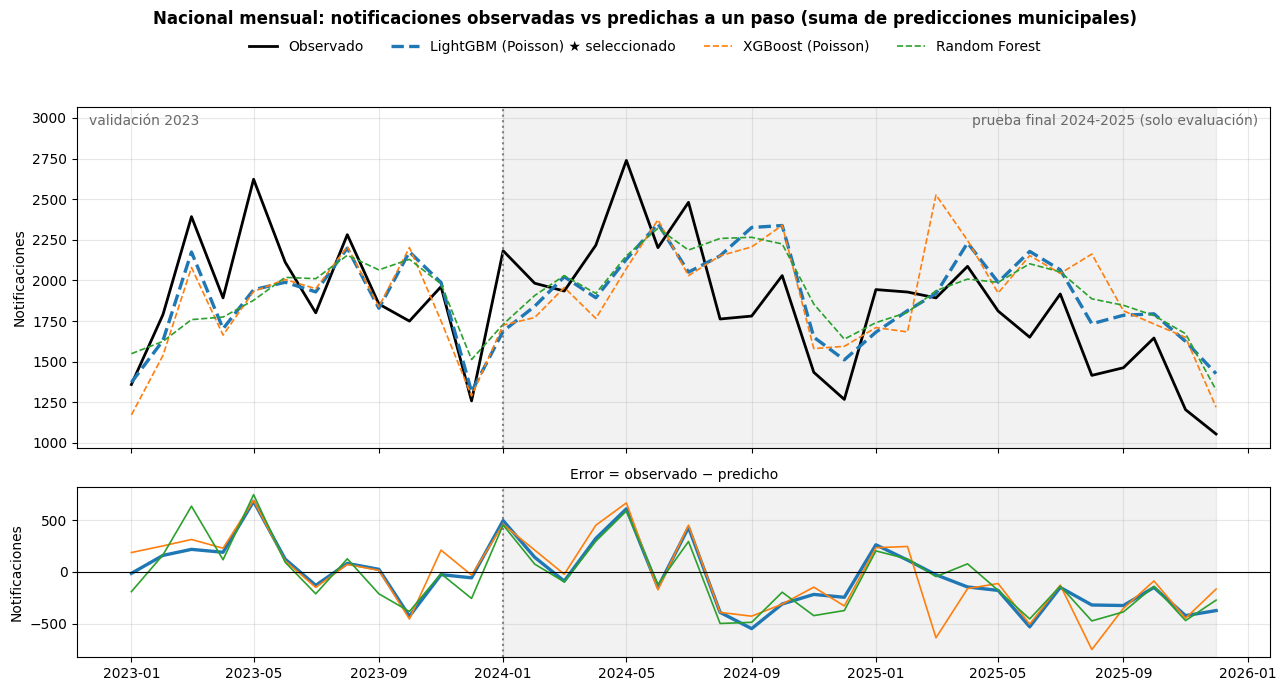

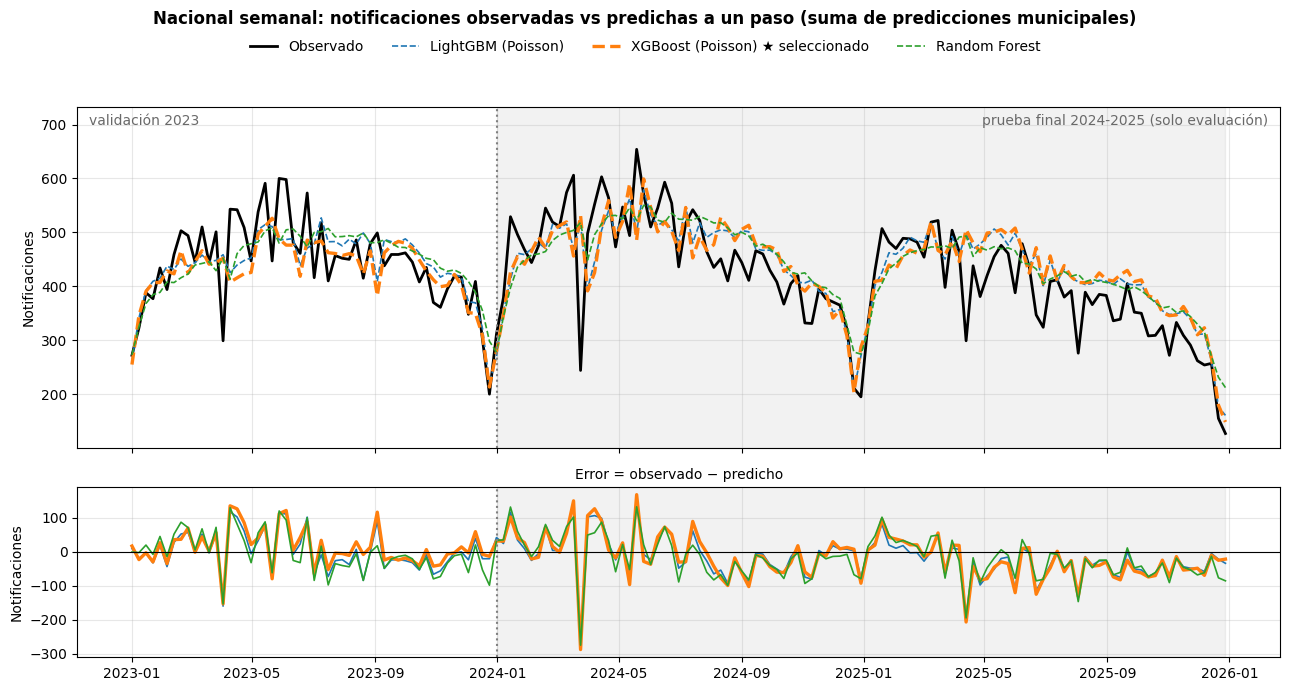

In [7]:
CRITERIO_SELECCION = 'RMSE'      # métrica de VALIDACIÓN (menor = mejor) que elige el modelo; fijada a priori
MET = ['MAE', 'RMSE', 'R2', 'WMAPE']
NIVELES = {'Municipal': ['DIVIPOLA_RESIDENCIA'], 'Departamental': ['COD_DPTO_S'], 'Nacional': []}

def niveles_de(freq):
    """(nivel, claves de agregación, filtro de filas). Semanal añade 'Municipal (estables)' (elegibilidad medida solo con 2017-2022)."""
    n = [('Municipal', NIVELES['Municipal'], None)]
    if freq == 'W': n.append(('Municipal (estables)', NIVELES['Municipal'], lambda d: d['TIER_SEM'] == 'ESTABLE'))
    return n + [('Departamental', NIVELES['Departamental'], None), ('Nacional', NIVELES['Nacional'], None)]

DATOS = {}
for freq in FREQ:
    d = pd.read_parquet(RUTAS[f'pred_{freq}']); d['COD_DPTO_S'] = d['DIVIPOLA_RESIDENCIA'].str[:2]
    assert d.loc[d['SPLIT'].isin(['val', 'test']), PRED_COLS].notna().all().all(), 'Faltan predicciones en validación o prueba'
    DATOS[freq] = d

def evaluar_todo(split):
    """Métricas de los tres modelos por frecuencia y nivel en la partición `split` (mismas filas para los tres modelos)."""
    filas = []
    for freq, d in DATOS.items():
        for nivel, keys, filtro in niveles_de(freq):
            m, n = evaluar_nivel(d if filtro is None else d[filtro(d)], PRED_COLS, keys, FREQ[freq]['fecha'], split)
            if n == 0: continue                                  # nivel sin observaciones en esta partición
            filas += [{'Frecuencia': FREQ[freq]['nombre'], 'Nivel': nivel, 'Clave': k, 'Modelo': MODELOS[k]['nombre'], f'n_{split}': n,
                       **{f'{a}_{split}': m.loc[k, a] for a in MET}} for k in PRED_COLS]
    return pd.DataFrame(filas)

# ---- 1. VALIDACIÓN 2023: elegir el mejor modelo (la prueba todavía no se ha calculado) ----
TV = evaluar_todo('val')
TV['Mejor_val'] = TV.index.isin(TV.groupby(['Frecuencia', 'Nivel'])[f'{CRITERIO_SELECCION}_val'].idxmin())
SEL = leer_json(RUTAS['seleccion'])
for freq in FREQ:
    g = TV[(TV['Frecuencia'] == FREQ[freq]['nombre']) & TV['Mejor_val']]
    s = g[g['Nivel'] == 'Municipal'].iloc[0]
    SEL[freq]['seleccionado'] = dict(clave=s['Clave'], nombre=s['Modelo'], nivel='Municipal', criterio=f'menor {CRITERIO_SELECCION} en validación 2023')
    SEL[freq]['mejor_validacion_por_nivel'] = dict(zip(g['Nivel'], g['Modelo']))
guardar_json(SEL, RUTAS['seleccion'])                          # selección congelada ANTES de mirar la prueba
print(f'MODELO SELECCIONADO (menor {CRITERIO_SELECCION} en validación 2023, nivel municipal; es el que usan las etapas 5 y 6):')
for freq in FREQ: print(f"  {FREQ[freq]['nombre']:<8}: {SEL[freq]['seleccionado']['nombre']}")

# ---- 2. PRUEBA FINAL 2024-2025: evaluación única, sin cambiar la selección ----
TT = evaluar_todo('test')
T = TV.merge(TT.drop(columns='Modelo'), on=['Frecuencia', 'Nivel', 'Clave'])
T[['Frecuencia', 'Nivel', 'Modelo', 'Clave', 'Mejor_val', 'n_val', 'n_test'] + [f'{a}_val' for a in MET] + [f'{a}_test' for a in MET]].to_csv(RUTAS['tabla'], index=False, encoding='utf-8-sig')

cols_m = pd.MultiIndex.from_tuples([('Validación 2023 (elige)', a) for a in MET] + [('Prueba 2024-2025 (evaluación final)', a) for a in MET])
for (fr, nv), g in T.groupby(['Frecuencia', 'Nivel'], sort=False):
    g = g.sort_values(f'{CRITERIO_SELECCION}_val')
    x = pd.DataFrame(g[[f'{a}_val' for a in MET] + [f'{a}_test' for a in MET]].to_numpy(), columns=cols_m,
                     index=[m + ('  ★' if b_ else '') for m, b_ in zip(g['Modelo'], g['Mejor_val'])])
    print(f"\n{fr.upper()} · nivel {nv.lower()} · {g['n_val'].iloc[0]:,} observaciones en validación / {g['n_test'].iloc[0]:,} en prueba · WMAPE en %; R² = 1 ajuste perfecto, ≤ 0 no mejora a predecir la media")
    display(x.round(3))

# ---- 3. Gráficos: observado vs predicho (nacional, suma de predicciones municipales) y error ----
COLORES = {'PRED_LGB': '#1f77b4', 'PRED_XGB': '#ff7f0e', 'PRED_RF': '#2ca02c'}
for freq in FREQ:
    d = DATOS[freq]; f = FREQ[freq]['fecha']; sel = SEL[freq]['seleccionado']['clave']
    nac = d[d['SPLIT'].isin(['val', 'test'])].groupby(f)[['CASOS'] + PRED_COLS].sum()
    t0 = pd.Timestamp(f'{ANIOS_TEST[0]}-01-01')
    fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
    ax[0].plot(nac.index, nac['CASOS'], 'k-', lw=2, label='Observado')
    for k in PRED_COLS:
        lw = 2.4 if k == sel else 1.2
        ax[0].plot(nac.index, nac[k], '--', color=COLORES[k], lw=lw, label=MODELOS[k]['nombre'] + (' ★ seleccionado' if k == sel else ''))
        ax[1].plot(nac.index, nac['CASOS'] - nac[k], color=COLORES[k], lw=lw)
    for a in ax:
        a.axvspan(t0, nac.index.max(), color='grey', alpha=0.10); a.axvline(t0, color='grey', ls=':')
    ax[1].axhline(0, color='k', lw=0.8)
    ax[0].set_ylim(top=nac.max().max() * 1.12)
    ax[0].text(0.01, 0.98, 'validación 2023', transform=ax[0].transAxes, va='top', color='dimgray')
    ax[0].text(0.99, 0.98, 'prueba final 2024-2025 (solo evaluación)', transform=ax[0].transAxes, va='top', ha='right', color='dimgray')
    ax[0].set_ylabel('Notificaciones'); ax[1].set_ylabel('Notificaciones'); ax[1].set_title('Error = observado − predicho', fontsize=10)
    fig.suptitle(f"Nacional {FREQ[freq]['nombre']}: notificaciones observadas vs predichas a un paso (suma de predicciones municipales)", fontweight='bold')
    h_, l_ = ax[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc='upper center', bbox_to_anchor=(0.5, 0.955), ncol=4, frameon=False)
    plt.tight_layout(rect=[0, 0, 1, 0.91]); plt.show()

### Cómo leer estos resultados
- **Unidad:** notificaciones (conteos) por municipio y periodo. Los análisis mensual y semanal son independientes: sus métricas no se comparan entre sí. Departamental y nacional son **sumas de las predicciones municipales**, no modelos distintos.
- **Periodo de evaluación:** validación 2023 (modelos entrenados con 2017-2022) y prueba final 2024-2025 (mismos hiperparámetros, re-ajustados con 2017-2023). Predicción **a un paso**: usa los casos observados hasta el periodo anterior; no es un pronóstico a varios periodos.
- **Selección:** solo con validación. La prueba se calculó una vez, después de guardar la selección, y no cambió ninguna decisión.
- **Limitaciones:** (1) son notificaciones al sistema de vigilancia, no incidencia real ni riesgo individual; (2) sin identificador de paciente no se pueden confirmar duplicados ni contar niños distintos; (3) la mayoría de municipios tiene pocos casos por periodo, por lo que el error relativo municipal es alto y no es comparable con el departamental o el nacional; (4) `ANO`/`SEMANA` se usan tal como vienen, aunque difieren de `FEC_NOT` en parte de los registros (etapa 1); (5) hay una única partición temporal: diferencias pequeñas entre los tres modelos no son concluyentes; (6) R² se calcula sobre las observaciones de cada nivel (en el nivel nacional mensual de validación son solo 12 puntos), por lo que ahí es inestable.

## 5. Pronóstico exploratorio de 12 meses (recursivo, no validado)
Usa el **modelo mensual seleccionado en validación** (uno de los tres), re-ajustado con todos los datos hasta el último mes observado (incluye 2024-2025; solo sirve para pronosticar y no participa en ninguna selección). El pronóstico es **recursivo**: cada mes predicho alimenta las variables del siguiente, así que **el error se acumula con el horizonte**. Los modelos se evaluaron únicamente a **un paso**: estas cifras **no son un resultado validado**. Alimentan el componente de volumen de la priorización (etapa 6).

Para el horizonte 2026-2030 ver la etapa 5b.

In [8]:
H_CORTO = 12
SEL = leer_json(RUTAS['seleccion']); clave_M = SEL['M']['seleccionado']['clave']; nombre_M = SEL['M']['seleccionado']['nombre']
panel = cargar_panel('M'); FEATS = lista_features('M'); dml = pd.read_parquet(RUTAS['ml_M'])
modelo_cp = ModeloTasa(MODELOS[clave_M]['crear']('M').set_params(**SEL['M']['parametros'][clave_M]), FREQ['M']['col_base']).fit(dml[FEATS], dml['CASOS'])

def pronostico_recursivo(panel, modelo, h_max):
    """Pronóstico mes a mes: cada mes predicho se añade a la serie y alimenta las variables del siguiente (sin ver el futuro)."""
    cols = ['CASOS', 'CASOS_RURAL', 'CASOS_INDIGENA']
    ext = panel[['DIVIPOLA_RESIDENCIA', 'ANIO_MES_DT'] + cols].copy(); ext[cols] = ext[cols].astype(float)
    unidades = ext['DIVIPOLA_RESIDENCIA'].unique(); ult_mes = ext['ANIO_MES_DT'].max()
    for h in range(1, h_max + 1):
        nuevo = ult_mes + pd.DateOffset(months=h)
        ext = pd.concat([ext, pd.DataFrame({'DIVIPOLA_RESIDENCIA': unidades, 'ANIO_MES_DT': nuevo, **{c: np.nan for c in cols}})], ignore_index=True)
        fh = construir_features(ext, 'M'); fh = fh[fh['ANIO_MES_DT'] == nuevo]
        m_ix = ext['ANIO_MES_DT'] == nuevo; idx = ext.loc[m_ix, 'DIVIPOLA_RESIDENCIA']
        alinear = lambda v: pd.Series(v, index=fh['DIVIPOLA_RESIDENCIA']).reindex(idx).to_numpy()
        casos = alinear(modelo.predict(fh[FEATS]))
        ext.loc[m_ix, 'CASOS'] = casos
        ext.loc[m_ix, 'CASOS_RURAL'] = casos * alinear(fh['PROP_RURAL_HIST'].to_numpy())
        ext.loc[m_ix, 'CASOS_INDIGENA'] = casos * alinear(fh['PROP_INDIGENA_HIST'].to_numpy())
    return ext[ext['ANIO_MES_DT'] > ult_mes][['DIVIPOLA_RESIDENCIA', 'ANIO_MES_DT', 'CASOS']].rename(columns={'CASOS': 'CASOS_ESPERADOS'})

corto = pronostico_recursivo(panel, modelo_cp, H_CORTO)
ultimos_12 = panel[panel['ANIO_MES_DT'] > panel['ANIO_MES_DT'].max() - pd.DateOffset(months=12)]['CASOS'].sum()
print(f"[PRONÓSTICO EXPLORATORIO] {corto['ANIO_MES_DT'].min():%Y-%m} a {corto['ANIO_MES_DT'].max():%Y-%m} | modelo: {nombre_M} | "
      f"notificaciones esperadas (suma municipal): {corto['CASOS_ESPERADOS'].sum():,.0f} | observadas en los 12 meses previos: {ultimos_12:,.0f}")
print('Recursivo: el error se acumula con el horizonte y no se validó a más de un paso.')

[PRONÓSTICO EXPLORATORIO] 2026-01 a 2026-12 | modelo: LightGBM (Poisson) | notificaciones esperadas (suma municipal): 20,543 | observadas en los 12 meses previos: 20,018
Recursivo: el error se acumula con el horizonte y no se validó a más de un paso.


## 5b. Escenarios anuales 2026-2030 (planeación; no son los tres modelos y no están validados)
**Este bloque no usa LightGBM, XGBoost ni Random Forest**: los árboles no extrapolan tendencias y el pronóstico recursivo a 5 años acumularía demasiado error, además de que solo se evaluaron a un paso. Aquí se proyecta el **total anual de notificaciones** con un método de tendencia con supuestos explícitos: nivel base (media de los últimos años completos) × crecimiento anual por departamento (pendiente log-lineal, encogida hacia la nacional, con tope y amortiguación), en tres escenarios (bajo / central / alto). Los escenarios bajo y alto (±5 pp anuales) y la incertidumbre que crece con √horizonte son **supuestos**, no estimaciones. Solo se contrasta el método con una **retro-validación** de totales anuales departamentales; no valida el horizonte 2026-2030. Todo trata notificaciones, no incidencia real ni riesgo individual.

In [9]:
# ---------------- PARÁMETROS Y SUPUESTOS (editables) ----------------
ANIOS_PROY = (2026, 2030)
ANIOS_BASE = 2          # años completos promediados como nivel base
ANIOS_TEND = 4          # años completos para estimar la tendencia departamental
TOPE_CRECIMIENTO = 0.10 # tope de variación anual del escenario central (±10 %)
DELTA_ESCENARIO = 0.05  # bajo/alto = central -/+ 5 puntos porcentuales de crecimiento anual (SUPUESTO, no estimado)
AMORTIGUACION = 0.85    # el crecimiento se reduce 15 % cada año (evita extrapolar tendencias a 5 años)
K_ENCOGIMIENTO = 300    # casos: un depto con pocos casos hereda más del crecimiento nacional
Z80 = 1.2816

pa = panel.assign(ANIO=panel['ANIO_MES_DT'].dt.year)
nom_mun = pa.drop_duplicates('DIVIPOLA_RESIDENCIA').set_index('DIVIPOLA_RESIDENCIA')[['Departamento_residencia', 'Municipio_residencia']]
nom_dep = pa.assign(C=pa['DIVIPOLA_RESIDENCIA'].str[:2]).drop_duplicates('C').set_index('C')['Departamento_residencia']
meses = pa.groupby('ANIO')['ANIO_MES_DT'].nunique()
anios_ok = sorted(meses[meses == 12].index.tolist())
anual = pa[pa['ANIO'].isin(anios_ok)].groupby(['DIVIPOLA_RESIDENCIA', 'ANIO'])['CASOS'].sum().unstack(fill_value=0)
ult = anios_ok[-1]

def tasa_log(v, anios):
    return np.expm1(np.polyfit(np.array(anios, float), np.log(np.asarray(v, float) + 1), 1)[0])

def crecimiento(anual_t, anios_t):
    "Crecimiento anual central por departamento: pendiente log-lineal encogida hacia la nacional y con tope."
    at = anios_t[-ANIOS_TEND:]
    tot = anual_t[at].groupby(anual_t.index.str[:2]).sum()
    g_nac = tasa_log(tot.sum().values, at)
    g_dep = tot.apply(lambda r: tasa_log(r.values, at), axis=1)
    n = tot.sum(1); w = n / (n + K_ENCOGIMIENTO)
    return (w * g_dep + (1 - w) * g_nac).clip(-TOPE_CRECIMIENTO, TOPE_CRECIMIENTO), float(np.clip(g_nac, -TOPE_CRECIMIENTO, TOPE_CRECIMIENTO))

def trayectoria(base, g, hs, delta=0.0):
    "Nivel proyectado a cada horizonte h (años después del último completo); el nivel base está centrado (ANIOS_BASE-1)/2 años antes del último año."
    gg = (g + delta).clip(-TOPE_CRECIMIENTO - DELTA_ESCENARIO, TOPE_CRECIMIENTO + DELTA_ESCENARIO)
    off = (ANIOS_BASE - 1) / 2; out = {}
    for h in hs:
        inc = [np.log1p(gg * AMORTIGUACION ** (k - 1)) for k in range(1, h + 1)]
        out[h] = base * np.exp(sum(inc) + off * inc[0])
    return pd.DataFrame(out)

# --- Retro-validación del MÉTODO (proyectar desde años pasados y comparar con lo ocurrido) ---
errs = {'dep': {}, 'nal': {}}
for T_ in [a for a in anios_ok if anios_ok[ANIOS_TEND - 1] <= a < ult]:
    at_ = [a for a in anios_ok if a <= T_]; an_ = anual[at_]
    g, _ = crecimiento(an_, at_)
    cod = an_.index.str[:2]; dep_all = anual.groupby(cod).sum()
    base_d = an_[at_[-ANIOS_BASE:]].groupby(cod).sum().mean(1)
    hs_bt = [a - T_ for a in anios_ok if a > T_]
    pr = trayectoria(base_d, g.reindex(base_d.index), hs_bt)
    for h in hs_bt:
        act = dep_all[T_ + h].reindex(pr.index)
        errs['dep'].setdefault(h, []).extend(np.log((act + 1) / (pr[h] + 1)).tolist())
        errs['nal'].setdefault(h, []).append(float(np.log((act.sum() + 1) / (pr[h].sum() + 1))))

def sd_rob(x):
    x = np.asarray(x); return 1.4826 * np.median(np.abs(x - np.median(x)))

def sigma1(e):
    "σ1 de la incertidumbre log (σ_h = σ1·√h), ponderando por número de pares y horizonte."
    hs_ = sorted(e); n = np.array([len(e[h]) for h in hs_]); s_ = np.array([sd_rob(e[h]) for h in hs_])
    return float((n * s_ * np.sqrt(hs_)).sum() / (n * np.array(hs_)).sum()), hs_, n, s_

S1_dep, hs_, n_, s_ = sigma1(errs['dep']); S1_nal = sigma1(errs['nal'])[0]
bt = pd.DataFrame({'h': hs_, 'n_pares_depto': n_, 'sd_robusto_log': s_.round(3), 'sesgo_mediano_log': [round(float(np.median(errs['dep'][h])), 3) for h in hs_]})

# --- Proyección: 3 escenarios por municipio, agregados a departamento y nación ---
hs = list(range(1, ANIOS_PROY[1] - ult + 1)); anios_p = [ult + h for h in hs]
g_dep, g_nac = crecimiento(anual, anios_ok)
cod_m = pd.Series(anual.index.str[:2], index=anual.index)
base_m = anual[anios_ok[-ANIOS_BASE:]].mean(1)
g_m = cod_m.map(g_dep).astype(float)
ESC = {'BAJO': -DELTA_ESCENARIO, 'CENTRAL': 0.0, 'ALTO': DELTA_ESCENARIO}
PM = {e: trayectoria(base_m, g_m, hs, dl).set_axis(anios_p, axis=1) for e, dl in ESC.items()}
PD = {e: PM[e].groupby(cod_m).sum() for e in ESC}; PN = {e: PM[e].sum() for e in ESC}
sig_h = {h: S1_dep * np.sqrt(h) for h in hs}; sig_h_n = {h: S1_nal * np.sqrt(h) for h in hs}

nacional = pd.DataFrame([{'ANIO': a, 'ESCENARIO': e, 'PROYECCION': PN[e][a]} for e in ESC for a in anios_p])
nacional = nacional.pivot(index='ANIO', columns='ESCENARIO', values='PROYECCION')[['BAJO', 'CENTRAL', 'ALTO']]
nacional['IC80_BAJO'] = [nacional.loc[a, 'CENTRAL'] * np.exp(-Z80 * sig_h_n[a - ult]) for a in nacional.index]
nacional['IC80_ALTO'] = [nacional.loc[a, 'CENTRAL'] * np.exp(Z80 * sig_h_n[a - ult]) for a in nacional.index]

dep_proy = pd.DataFrame([{'COD_DPTO': cdp, 'DEPARTAMENTO': nom_dep.get(cdp, ''), 'ANIO': a, 'ESCENARIO': e, 'PROYECCION': PD[e].loc[cdp, a],
                          'IC80_BAJO': PD[e].loc[cdp, a] * np.exp(-Z80 * sig_h[a - ult]) if e == 'CENTRAL' else np.nan,
                          'IC80_ALTO': PD[e].loc[cdp, a] * np.exp(Z80 * sig_h[a - ult]) if e == 'CENTRAL' else np.nan}
                         for e in ESC for cdp in PD[e].index for a in anios_p])
mun = nom_mun.reindex(anual.index).reset_index()
mun['CASOS_BASE'] = base_m.values
for e in ESC:
    for a in anios_p: mun[f'PROY_{a}_{e}'] = PM[e][a].values
for a in anios_p:       # P10-P90 municipal del central: Poisson + incertidumbre de nivel (binomial negativa con α = exp(σ²) − 1)
    mu = np.clip(PM['CENTRAL'][a].values, 1e-9, None); n = 1 / (np.exp(sig_h[a - ult] ** 2) - 1)
    mun[f'PROY_{a}_P10'] = nbinom.ppf(0.1, n, n / (n + mu)); mun[f'PROY_{a}_P90'] = nbinom.ppf(0.9, n, n / (n + mu))
mun['COD_DPTO'] = mun['DIVIPOLA_RESIDENCIA'].str[:2]; mun['CRECIMIENTO_ANUAL_CENTRAL'] = g_m.values.round(4)

print(f"[ESCENARIOS {anios_p[0]}-{anios_p[-1]}] años completos usados: {anios_ok[0]}-{ult} | notificaciones observadas {ult}: {int(anual[ult].sum()):,}")
print('Proyección nacional de notificaciones (3 escenarios + IC80 del central):')
display(nacional.round(0).astype(int))
print(f"Crecimiento anual central nacional (antes de amortiguar): {g_nac:+.1%} | tope ±{TOPE_CRECIMIENTO:.0%} | escenarios ±{DELTA_ESCENARIO*100:.0f} pp")
print('Retro-validación del método (error log de proyectar el total departamental h años adelante):'); display(bt)
print(f"σ1 departamental = {S1_dep:.3f} | σ1 nacional = {S1_nal:.3f} (σ_h = σ1·√h es un SUPUESTO; solo hay evidencia hasta h={max(hs_)} y no valida el horizonte proyectado).")
print(f"Comparación {ult + 1}: pronóstico de 12 meses (etapa 5, modelo seleccionado) = {corto['CASOS_ESPERADOS'].sum():,.0f} | escenario central = {nacional.loc[ult + 1, 'CENTRAL']:,.0f}")

[ESCENARIOS 2026-2030] años completos usados: 2016-2025 | notificaciones observadas 2025: 20,018
Proyección nacional de notificaciones (3 escenarios + IC80 del central):


ESCENARIO,BAJO,CENTRAL,ALTO,IC80_BAJO,IC80_ALTO
ANIO,,,,,
2026,20511,22143,23815,18149,27016
2027,19826,22336,25028,16859,29592
2028,19328,22573,26188,15994,31857
2029,18961,22827,27276,15335,33980
2030,18686,23083,28283,14795,36012


Crecimiento anual central nacional (antes de amortiguar): -1.3% | tope ±10% | escenarios ±5 pp
Retro-validación del método (error log de proyectar el total departamental h años adelante):


,h,n_pares_depto,sd_robusto_log,sesgo_mediano_log
0,1,198,0.376,-0.050
1,2,165,0.566,0.054
2,3,132,0.562,0.117
3,4,99,0.513,0.294
4,5,66,0.460,0.063
5,6,33,0.413,-0.301


σ1 departamental = 0.291 | σ1 nacional = 0.155 (σ_h = σ1·√h es un SUPUESTO; solo hay evidencia hasta h=6 y no valida el horizonte proyectado).
Comparación 2026: pronóstico de 12 meses (etapa 5, modelo seleccionado) = 20,543 | escenario central = 22,143


## 6. Priorización territorial y exportación
Índice **relativo** (cuartiles) que combina el **volumen esperado** (pronóstico exploratorio de la etapa 5) y la **composición territorial** (% rural / indígena de los casos notificados, con encogimiento hacia el % nacional). Si se aporta `RUTAS['poblacion']` (CSV `DIVIPOLA, POBLACION`) se añade la tasa por 100 mil; si no, no se inventa población. Las prioridades ordenan atención; no diagnostican ni miden riesgo individual. Exporta (incluidos los escenarios 2026-2030 de la etapa 5b) a `NUTRIPREDICT_COLOMBIA_RESULTADOS_2016_2025.xlsx` y `resultados_nutripredict_2016_2025.json`.

In [10]:
# ---------------- PARÁMETROS Y SUPUESTOS (editables) ----------------
K_PROP = 20                       # casos: encogimiento del % rural/indígena municipal hacia el % nacional
UMBRAL_BAJA_CONFIABILIDAD = 10    # casos notificados en los últimos 24 meses por debajo del cual el municipio se marca "baja confiabilidad"
PESOS_SIN_POB = {'vol': 0.50, 'rur': 0.25, 'ind': 0.25}
PESOS_CON_POB = {'vol': 0.20, 'tasa': 0.40, 'rur': 0.20, 'ind': 0.20}   # SUPUESTO experto: la tasa pesa más que el volumen

# =========================== A. PRIORIZACIÓN ===========================
ipr = (panel.drop_duplicates('DIVIPOLA_RESIDENCIA')[['DIVIPOLA_RESIDENCIA', 'Departamento_residencia', 'Municipio_residencia']]
            .sort_values('DIVIPOLA_RESIDENCIA').reset_index(drop=True))
d_test = pd.read_parquet(RUTAS['pred_M']); d_test = d_test[d_test['SPLIT'] == 'test']
ipr = ipr.merge(d_test.groupby('DIVIPOLA_RESIDENCIA').agg(CASOS_NOTIF_PRUEBA=('CASOS', 'sum'), CASOS_PRED_PRUEBA=(clave_M, 'sum')).reset_index(),
                on='DIVIPOLA_RESIDENCIA', how='left')
col_vol = 'ESPERADOS_12M'
ipr[col_vol] = ipr['DIVIPOLA_RESIDENCIA'].map(corto.groupby('DIVIPOLA_RESIDENCIA')['CASOS_ESPERADOS'].sum()).fillna(0)
ult24 = panel[panel['ANIO_MES_DT'] > panel['ANIO_MES_DT'].max() - pd.DateOffset(months=24)].groupby('DIVIPOLA_RESIDENCIA')['CASOS'].sum()
ipr['CASOS_ULT_2_ANIOS'] = ipr['DIVIPOLA_RESIDENCIA'].map(ult24).fillna(0)
tot = panel.groupby('DIVIPOLA_RESIDENCIA')[['CASOS', 'CASOS_RURAL', 'CASOS_INDIGENA']].sum().reindex(ipr['DIVIPOLA_RESIDENCIA'])
p_nac = tot[['CASOS_RURAL', 'CASOS_INDIGENA']].sum() / tot['CASOS'].sum()
COMP = [('CASOS_RURAL', 'RURAL'), ('CASOS_INDIGENA', 'INDIGENA')]
for col, nom in COMP: ipr[f'PROP_{nom}'] = (tot[col] / tot['CASOS'].where(tot['CASOS'] > 0)).fillna(0).values
for col, nom in COMP: ipr[f'PROP_{nom}_AJ'] = ((tot[col] + K_PROP * p_nac[col]) / (tot['CASOS'] + K_PROP)).values   # encogida hacia el % nacional

pob = leer_poblacion(); tiene_pob = False
if pob is not None:
    ipr = ipr.merge(pob[['DIVIPOLA_RESIDENCIA', 'POBLACION']], on='DIVIPOLA_RESIDENCIA', how='left')
    ipr['TASA_ESPERADA_100K'] = ipr[col_vol] / ipr['POBLACION'] * 1e5
    tiene_pob = ipr['TASA_ESPERADA_100K'].notna().mean() > 0.9

pct = lambda s: s.rank(pct=True, method='average')
def calc_ipr(df_, w):
    comp = {'vol': pct(np.log1p(df_[col_vol])), 'rur': pct(df_['PROP_RURAL_AJ']), 'ind': pct(df_['PROP_INDIGENA_AJ'])}
    if 'tasa' in w: comp['tasa'] = pct(df_['TASA_ESPERADA_100K'].fillna(0))
    return 100 * sum(w[k] * comp[k] for k in w), comp

W = PESOS_CON_POB if tiene_pob else PESOS_SIN_POB
ipr['IPR_SCORE'], comp = calc_ipr(ipr, W); ipr['IPR_SCORE'] = ipr['IPR_SCORE'].round(2)
ipr['COMP_VOLUMEN'] = (100 * comp['vol']).round(1)
if tiene_pob: ipr['COMP_TASA'] = (100 * comp['tasa']).round(1)
ipr['COMP_TERRITORIAL'] = (100 * (comp['rur'] + comp['ind']) / 2).round(1)
ipr['NIVEL_PRIORIDAD'] = pd.qcut(ipr['IPR_SCORE'].rank(method='first'), 4, labels=['BAJO', 'MEDIO', 'ALTO', 'CRÍTICO']).astype(str)
ipr['CONFIABILIDAD'] = np.where(ipr['CASOS_ULT_2_ANIOS'] < UMBRAL_BAJA_CONFIABILIDAD, 'BAJA', 'ADECUADA')
print(f"[PRIORIZACIÓN] pesos {'CON' if tiene_pob else 'SIN'} población: {W} | municipios con baja confiabilidad (< {UMBRAL_BAJA_CONFIABILIDAD} casos en 24 meses): "
      f"{(ipr['CONFIABILIDAD'] == 'BAJA').sum()} de {len(ipr)}")
if not tiene_pob:
    print("⚠️ Sin población DANE no hay tasa por 100 mil: el índice mezcla volumen esperado y composición de los casos. Define RUTAS['poblacion'] para incorporarla.")

# Sensibilidad: variantes de definición / ponderación frente al índice propuesto
orig = 100 * (0.5 * pct(np.log1p(ipr['CASOS_PRED_PRUEBA'].fillna(0))) + 0.25 * pct(ipr['PROP_RURAL']) + 0.25 * pct(ipr['PROP_INDIGENA']))
alt = {'Índice previo (casos predichos 2024-25, % sin ajustar)': orig, 'Solo volumen esperado': 100 * comp['vol'],
       'Solo territorial': 100 * (comp['rur'] + comp['ind']) / 2, 'Pesos iguales': 100 * sum(comp.values()) / len(comp)}
if tiene_pob: alt['Solo tasa'] = 100 * comp['tasa']
top = lambda s: set(s.nlargest(int(len(s) * 0.25)).index)
sens = pd.DataFrame([{'Alternativa': n_, 'Spearman vs índice propuesto': round(float(spearmanr(ipr['IPR_SCORE'], s_)[0]), 3),
                      '% coincidencia en el 25% superior': round(100 * len(top(ipr['IPR_SCORE']) & top(pd.Series(np.asarray(s_), index=ipr.index))) / int(len(ipr) * 0.25), 1)}
                     for n_, s_ in alt.items()])
display(sens)
ipr = ipr.sort_values('IPR_SCORE', ascending=False).reset_index(drop=True)
print('Top 10 (prioridad RELATIVA para análisis; no es riesgo individual):')
display(ipr[['Departamento_residencia', 'Municipio_residencia', col_vol, 'CASOS_ULT_2_ANIOS', 'PROP_RURAL_AJ', 'PROP_INDIGENA_AJ', 'IPR_SCORE', 'NIVEL_PRIORIDAD', 'CONFIABILIDAD']].head(10).round(2))

# =========================== B. EXPORTACIÓN ===========================
sup = pd.DataFrame([
 ('Unidad', 'NOTIFICACIONES (filas del evento 113), no incidencia real ni riesgo individual'),
 ('Modelos comparados', 'LightGBM (Poisson), XGBoost (Poisson) y Random Forest; hiperparámetros y mejor modelo elegidos con entrenamiento 2017-2022 y validación 2023; prueba 2024-2025 solo evalúa'),
 ('Modelo seleccionado', f"Mensual: {SEL['M']['seleccionado']['nombre']} | Semanal: {SEL['W']['seleccionado']['nombre']} (menor {CRITERIO_SELECCION} en validación, nivel municipal)"),
 ('Pronóstico 12 meses (EXPLORATORIO)', f"Recursivo con {nombre_M} re-ajustado con datos hasta {panel['ANIO_MES_DT'].max():%Y-%m}; el error se acumula y NO se validó a más de un paso"),
 ('Escenarios 2026-2030 (NO son los tres modelos)', f'Nivel base = media de los últimos {ANIOS_BASE} años completos; crecimiento = pendiente log-lineal de {ANIOS_TEND} años por departamento, encogida hacia la nacional (K={K_ENCOGIMIENTO}), tope ±{TOPE_CRECIMIENTO:.0%}, amortiguado x{AMORTIGUACION} por año'),
 ('Escenarios bajo / alto', f'Central ∓ {DELTA_ESCENARIO*100:.0f} pp anuales (supuesto de planeación, no estimado)'),
 ('Incertidumbre de los escenarios', f'IC80 del central: log-normal con σ_h = σ1·√h, σ1 depto={S1_dep:.3f}, nacional={S1_nal:.3f} (supuesto; retro-validación solo hasta h={max(hs_)})'),
 ('Índice de prioridad', f'Pesos {W} (supuesto de planeación); percentiles relativos entre municipios'),
 ('Supuestos NO verificables', 'Constancia de la definición de caso y de la capacidad de notificación; codificación SIVIGILA de AREA y PER_ETN; sin variables socioeconómicas ni población si no se aporta'),
], columns=['Elemento', 'Supuesto'])
notas = pd.DataFrame({'Nota': [
 'Todas las cifras son notificaciones al sistema de vigilancia; no equivalen a incidencia ni a riesgo individual.',
 'Los índices de prioridad son relativos entre municipios (cuartiles) y sirven para ordenar atención, no para diagnosticar.',
 'PROP_RURAL / PROP_INDIGENA describen la composición de los casos notificados, no del municipio.',
 'Municipios con CONFIABILIDAD = BAJA tienen muy pocos casos: su índice es inestable.',
 'El pronóstico de 12 meses es recursivo y exploratorio: no está validado; CASOS_REALES / CASOS_PRED corresponden a la prueba 2024-2025 con un paso adelante.',
 'Los escenarios 2026-2030 son extrapolaciones de tendencia con supuestos explícitos: no provienen de los tres modelos y su horizonte no está validado.',
 'Resultados de validación y prueba: hoja Resumen_Modelos (validación 2023 elige; prueba 2024-2025 solo evalúa).']})
cal_q = leer_json(RUTAS['calidad'])
calidad_df = pd.json_normalize({k: v for k, v in cal_q.items() if k != 'fechas_por_ano_archivo'}).T.reset_index().rename(columns={'index': 'Indicador', 0: 'Valor'})
with pd.ExcelWriter(RUTAS['excel_res']) as w_:
    pd.read_csv(RUTAS['tabla']).to_excel(w_, sheet_name='Resumen_Modelos', index=False)
    calidad_df.astype(str).to_excel(w_, sheet_name='Calidad_Datos', index=False)
    pd.DataFrame(cal_q.get('fechas_por_ano_archivo', [])).to_excel(w_, sheet_name='Calidad_Fechas', index=False)
    sup.to_excel(w_, sheet_name='Supuestos', index=False)
    bt.to_excel(w_, sheet_name='Retrovalidacion_proyeccion', index=False)
    nacional.reset_index().to_excel(w_, sheet_name='Proy_Nacional', index=False)
    dep_proy.to_excel(w_, sheet_name='Proy_Departamental', index=False)
    mun.drop(columns=['COD_DPTO']).to_excel(w_, sheet_name='Proy_Municipal', index=False)
    corto.pivot(index='DIVIPOLA_RESIDENCIA', columns='ANIO_MES_DT', values='CASOS_ESPERADOS').round(2).to_excel(w_, sheet_name='Pronostico_12m_exploratorio')
    ipr.to_excel(w_, sheet_name='Priorizacion_IPR_Municipal', index=False)
    sens.to_excel(w_, sheet_name='Sensibilidad_IPR', index=False)
    notas.to_excel(w_, sheet_name='Notas', index=False)

pm_ = mun.set_index('DIVIPOLA_RESIDENCIA'); fin_a = anios_p[-1]
salida = [{
    "DIVIPOLA": str(r['DIVIPOLA_RESIDENCIA']), "DPTO": str(r['Departamento_residencia']), "MUNICIPIO": str(r['Municipio_residencia']),
    "CASOS_REALES": int(r['CASOS_NOTIF_PRUEBA']) if pd.notna(r['CASOS_NOTIF_PRUEBA']) else 0,
    "CASOS_PRED": int(round(r['CASOS_PRED_PRUEBA'])) if pd.notna(r['CASOS_PRED_PRUEBA']) else 0,
    f"PROY_{fin_a}": int(round(pm_.loc[r['DIVIPOLA_RESIDENCIA'], f'PROY_{fin_a}_CENTRAL'])),
    f"PROY_{fin_a}_BAJO": int(round(pm_.loc[r['DIVIPOLA_RESIDENCIA'], f'PROY_{fin_a}_BAJO'])),
    f"PROY_{fin_a}_ALTO": int(round(pm_.loc[r['DIVIPOLA_RESIDENCIA'], f'PROY_{fin_a}_ALTO'])),
    f"PROY_{fin_a}_P10": int(pm_.loc[r['DIVIPOLA_RESIDENCIA'], f'PROY_{fin_a}_P10']), f"PROY_{fin_a}_P90": int(pm_.loc[r['DIVIPOLA_RESIDENCIA'], f'PROY_{fin_a}_P90']),
    "ESPERADOS_SIGUIENTE_ANIO": round(float(r[col_vol]), 1),
    "TASA_100K": round(float(r['TASA_ESPERADA_100K']), 1) if tiene_pob and pd.notna(r.get('TASA_ESPERADA_100K')) else None,
    "RURAL": f"{round(r['PROP_RURAL'] * 100, 1)}%", "INDIGENA": f"{round(r['PROP_INDIGENA'] * 100, 1)}%",
    "IPR": float(r['IPR_SCORE']), "RANGO": str(r['NIVEL_PRIORIDAD']), "CONFIABILIDAD": str(r['CONFIABILIDAD'])} for r in ipr.to_dict('records')]
guardar_json(salida, RUTAS['json_php'], indent=4)
print(f"\nMunicipios exportados: {len(ipr)} | Excel: {RUTAS['excel_res']} | JSON: {RUTAS['json_php']}")

[PRIORIZACIÓN] pesos SIN población: {'vol': 0.5, 'rur': 0.25, 'ind': 0.25} | municipios con baja confiabilidad (< 10 casos en 24 meses): 555 de 1119
⚠️ Sin población DANE no hay tasa por 100 mil: el índice mezcla volumen esperado y composición de los casos. Define RUTAS['poblacion'] para incorporarla.


,Alternativa,Spearman vs índice propuesto,% coincidencia en el 25% superior
0,"Índice previo (casos predichos 2024-25, % sin ...",0.909,73.8
1,Solo volumen esperado,0.700,47.7
2,Solo territorial,0.201,51.3
3,Pesos iguales,0.687,80.3


Top 10 (prioridad RELATIVA para análisis; no es riesgo individual):


,Departamento_residencia,Municipio_residencia,ESPERADOS_12M,CASOS_ULT_2_ANIOS,PROP_RURAL_AJ,PROP_INDIGENA_AJ,IPR_SCORE,NIVEL_PRIORIDAD,CONFIABILIDAD
0,GUAJIRA,MANAURE,301.12,690,0.84,0.97,99.51,CRÍTICO,ADECUADA
1,GUAJIRA,URIBIA,537.95,1578,0.69,0.97,99.22,CRÍTICO,ADECUADA
2,RISARALDA,PUEBLO RICO,131.43,277,0.94,0.95,99.13,CRÍTICO,ADECUADA
3,VICHADA,CUMARIBO,109.21,285,0.88,0.97,98.77,CRÍTICO,ADECUADA
4,CESAR,AGUSTIN CODAZZI,116.29,398,0.63,0.67,96.98,CRÍTICO,ADECUADA
5,CESAR,PUEBLO BELLO,61.89,195,0.68,0.83,96.98,CRÍTICO,ADECUADA
6,CORDOBA,TUCHIN,46.09,49,0.81,0.86,96.69,CRÍTICO,ADECUADA
7,CHOCO,BAGADO,96.33,253,0.57,0.91,96.56,CRÍTICO,ADECUADA
8,GUAJIRA,RIOHACHA,356.20,1164,0.54,0.65,96.16,CRÍTICO,ADECUADA
9,RISARALDA,MISTRATO,38.50,87,0.87,0.88,96.16,CRÍTICO,ADECUADA



Municipios exportados: 1119 | Excel: /content/drive/MyDrive/NUTRIPREDICT_COLOMBIA_RESULTADOS_2016_2025.xlsx | JSON: /content/drive/MyDrive/resultados_nutripredict_2016_2025.json
